# NMR - Spin Echo

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch10/ch10-03.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** no setup is needed for this notebook. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

## Import libraries


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from mpl_toolkits.mplot3d import Axes3D

## Define parameters

In [9]:

# 1. PHYSICS CONFIGURATION
# ==========================================
Gamma = 268.0
B1_amp = 0.0004
T1 = 100000.0
T2 = 100000.0
TE = 4000.0

# Pulse Durations (Flip Angles)
dur90 = np.pi / (2.0 * Gamma * B1_amp)
dur180 = np.pi / (Gamma * B1_amp)

# Sequence Intervals: [Duration, Is_Pulse]
sequence = [
    (dur90, True),      # 1. Excitation (90)
    (TE/2, False),      # 2. Dephasing
    (dur180, True),     # 3. Refocusing (180)
    (TE, False),        # 4. Rephasing (Echo 1 at center)
    (dur180, True),     # 5. Refocusing (180)
    (TE, False)         # 6. Rephasing (Echo 2 at center)
]

# Spin System
n_spins = 19
indices = np.arange(1, n_spins + 1)
excess_B0_values = 0.0000005 * ((n_spins + 1)/2.0 - indices)

# Colors
colors = []
mid_idx = (n_spins - 1) // 2
for i in range(n_spins):
    if i < mid_idx: colors.append('darkred')
    elif i == mid_idx: colors.append('black')
    else: colors.append('darkgreen')

# ==========================================
# 2. BLOCH SOLVER
# ==========================================
def bloch_derivs(M_flat, t, B1, Omega_offsets):
    M = M_flat.reshape((n_spins, 3))
    Mx, My, Mz = M[:, 0], M[:, 1], M[:, 2]
    
    # Omega_z = Gamma * excess_B0
    w_z = Gamma * excess_B0_values
    w_1 = Gamma * B1
    
    dM = np.zeros_like(M)
    dM[:, 0] = -w_z * My - Mx/T2
    dM[:, 1] = w_z * Mx - w_1 * Mz - My/T2
    dM[:, 2] = w_1 * My + (1.0 - Mz)/T1
    
    return dM.flatten()

# Initial State
M_current = np.zeros((n_spins, 3))
M_current[:, 2] = 1.0
M_current = M_current.flatten()

# Storage
time_history = []
mag_history = []
pulse_history = []
current_time = 0.0

print("Simulating pulse sequence...")

for duration, is_pulse in sequence:
    n_steps = 100 if is_pulse else 300
    t_span = np.linspace(0, duration, n_steps)
    B1_val = B1_amp if is_pulse else 0.0
    
    sol = odeint(bloch_derivs, M_current, t_span, args=(B1_val, excess_B0_values))
    
    time_history.append(current_time + t_span)
    mag_history.append(sol)
    pulse_history.append(np.full(len(t_span), 1.0 if is_pulse else 0.0))
    
    M_current = sol[-1]
    current_time += duration

# Compile Data
full_time = np.concatenate(time_history)
full_mag = np.concatenate(mag_history)
full_pulse = np.concatenate(pulse_history)
M_viz = full_mag.reshape((len(full_time), n_spins, 3))

# Aggregates
Mx_net = np.mean(M_viz[:, :, 0], axis=1)
My_net = np.mean(M_viz[:, :, 1], axis=1)
Mz_net = np.mean(M_viz[:, :, 2], axis=1)
Mxy_mag = np.sqrt(Mx_net**2 + My_net**2)



Simulating pulse sequence...


## Plot

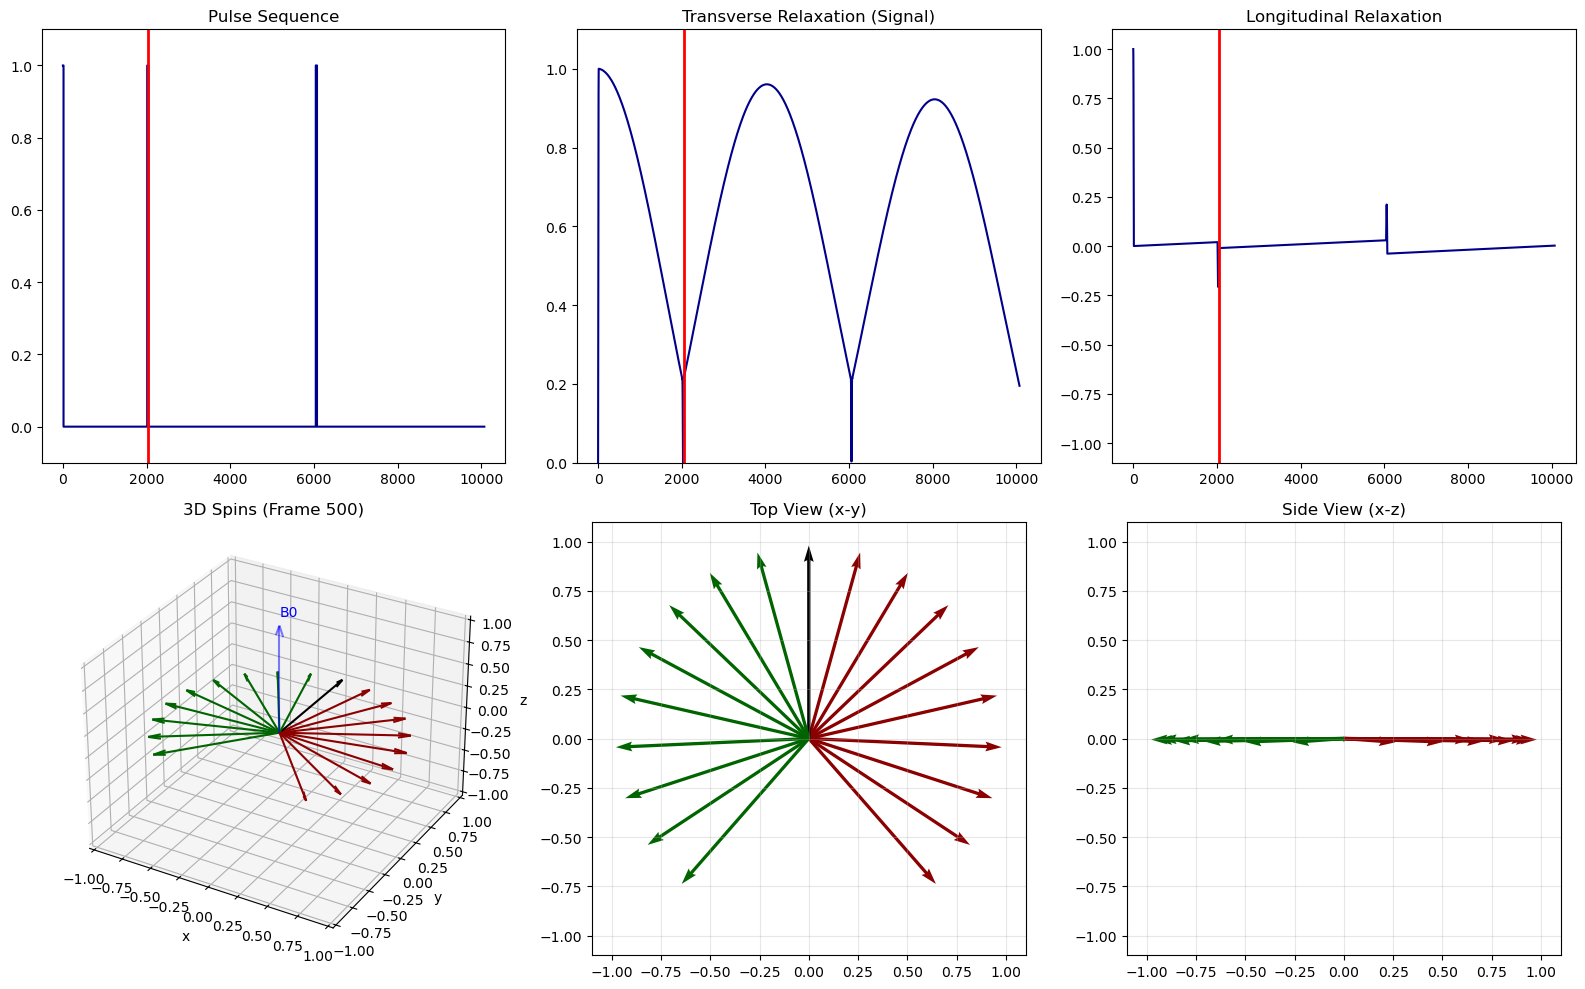

In [10]:
# ==========================================
# 3. SELECTION & PLOTTING
# ==========================================
frame_to_plot = 500  # <--- HARDCODED FRAME SELECTION
t_frame = full_time[frame_to_plot]
M_frame = M_viz[frame_to_plot]

fig1 = plt.figure(figsize=(16, 10))
plt.subplots_adjust(wspace=0.3, hspace=0.3)

# --- Top Row: Time Traces ---
# 1. Pulse
ax1 = fig1.add_subplot(2, 3, 1)
ax1.plot(full_time, full_pulse, color='darkblue')
ax1.axvline(t_frame, color='red', linewidth=2) # Current time marker
ax1.set_title("Pulse Sequence")
ax1.set_ylim(-0.1, 1.1)

# 2. Transverse Signal
ax2 = fig1.add_subplot(2, 3, 2)
ax2.plot(full_time, Mxy_mag, color='darkblue')
ax2.axvline(t_frame, color='red', linewidth=2)
ax2.set_title("Transverse Relaxation (Signal)")
ax2.set_ylim(0, 1.1)

# 3. Longitudinal
ax3 = fig1.add_subplot(2, 3, 3)
ax3.plot(full_time, Mz_net, color='darkblue')
ax3.axvline(t_frame, color='red', linewidth=2)
ax3.set_title("Longitudinal Relaxation")
ax3.set_ylim(-1.1, 1.1)

# --- Bottom Row: Snapshot at 'frame_to_plot' ---
# 4. 3D View
ax4 = fig1.add_subplot(2, 3, 4, projection='3d')
ax4.set_title(f"3D Spins (Frame {frame_to_plot})")
ax4.quiver(0, 0, 0, 0, 0, 1.2, color='blue', alpha=0.5, arrow_length_ratio=0.1)
ax4.text(0, 0, 1.3, "B0", color='blue')

for i in range(n_spins):
    vec = M_frame[i]
    ax4.quiver(0, 0, 0, vec[0], vec[1], vec[2], color=colors[i], length=1.0, arrow_length_ratio=0.1)

ax4.set_xlim(-1, 1); ax4.set_ylim(-1, 1); ax4.set_zlim(-1, 1)
ax4.set_xlabel('x'); ax4.set_ylabel('y'); ax4.set_zlabel('z')

# 5. Top View (X-Y)
ax5 = fig1.add_subplot(2, 3, 5)
ax5.set_title("Top View (x-y)")
ax5.set_xlim(-1.1, 1.1); ax5.set_ylim(-1.1, 1.1); ax5.set_aspect('equal')
ax5.grid(True, alpha=0.3)
ax5.quiver(np.zeros(n_spins), np.zeros(n_spins), M_frame[:, 0], M_frame[:, 1], color=colors, scale=1, scale_units='xy', angles='xy')

# 6. Side View (X-Z)
ax6 = fig1.add_subplot(2, 3, 6)
ax6.set_title("Side View (x-z)")
ax6.set_xlim(-1.1, 1.1); ax6.set_ylim(-1.1, 1.1); ax6.set_aspect('equal')
ax6.grid(True, alpha=0.3)
ax6.quiver(np.zeros(n_spins), np.zeros(n_spins), M_frame[:, 0], M_frame[:, 2], color=colors, scale=1, scale_units='xy', angles='xy')

plt.tight_layout()
plt.show()

## Make interactive using ipywidgets

In [ ]:
# ==========================================
# 3. INTERACTIVE UPDATE LOOP
# ==========================================
def update_dashboard(T2_val, TE_val, frame_idx):
    
    # A. Check if Physics changed
    params = (T2_val, TE_val)
    if sim_cache.get('params') != params:
        t, M, p, echos = compute_spin_echo(T2_val, TE_val)
        
        # Precompute Aggregates
        mx_net = np.mean(M[:,:,0], axis=1)
        my_net = np.mean(M[:,:,1], axis=1)
        mz_net = np.mean(M[:,:,2], axis=1)
        mxy_mag = np.sqrt(mx_net**2 + my_net**2)
        
        sim_cache['params'] = params
        sim_cache['data'] = (t, M, p, mxy_mag, mz_net, echos)
        
        # Update Static Curves
        plot_refs['lines'][0].set_data(t, p)
        plot_refs['lines'][1].set_data(t, mxy_mag)
        plot_refs['lines'][2].set_data(t, mz_net)
        
        # Reset Axis Limits
        for i in range(3):
            plot_refs['axes'][i].set_xlim(0, t[-1])
            
        # *** FIX: Update BOTH Slider and Play max limits ***
        new_max = len(t) - 1
        if frame_slider.max != new_max:
            frame_slider.max = new_max
        if play.max != new_max:
            play.max = new_max
            
    # B. Retrieve Data
    t, M, _, _, _, _ = sim_cache['data']
    
    # C. Handle Time Index
    safe_idx = min(frame_idx, len(t)-1)
    t_now = t[safe_idx]
    M_now = M[safe_idx] 
    
    # D. Update Markers
    for vm in plot_refs['vlines']:
        vm.set_xdata([t_now])
        
    # E. Update Quivers
    plot_refs['quivers'][0].set_UVC(M_now[:,0], M_now[:,1])
    plot_refs['quivers'][1].set_UVC(M_now[:,0], M_now[:,2])
    
    # F. Update 3D 
    ax3 = plot_refs['axes'][3]
    if plot_refs.get('q3d_list'):
        for q in plot_refs['q3d_list']: q.remove()
    
    new_q_list = []
    # B0 Arrow
    new_q_list.append(ax3.quiver(0,0,0, 0,0,1.2, color='blue', alpha=0.3, arrow_length_ratio=0.1))
    # Spins
    for i in range(n_spins):
        v = M_now[i]
        q = ax3.quiver(0,0,0, v[0], v[1], v[2], color=colors[i], length=1.0, arrow_length_ratio=0.1)
        new_q_list.append(q)
    plot_refs['q3d_list'] = new_q_list
    
    ax3.set_title(f"3D Spins (t={t_now:.1f})")

    display(plot_refs['fig'])
    clear_output(wait=True)

# ==========================================
# 4. WIDGET SETUP
# ==========================================

# Initialize Figure first
fig2 = init_fig()

style = {'description_width': 'initial'}

# Define Widgets (Play button defined BEFORE linking)
play = widgets.Play(value=0, min=0, max=100, step=1, interval=100, description="Play")
frame_slider = widgets.IntSlider(min=0, max=100, value=0, description='Time Frame', layout=widgets.Layout(width='600px'))
s_T2 = widgets.FloatSlider(min=2000, max=200000, step=1000, value=100000, description='T2 Decay', style=style, layout=widgets.Layout(width='400px'))
s_TE = widgets.FloatSlider(min=1000, max=6000, step=500, value=4000, description='TE (Echo Time)', style=style, layout=widgets.Layout(width='400px'))

# Link Play and Slider
widgets.jslink((play, 'value'), (frame_slider, 'value'))

# Layout
ui = widgets.VBox([
    widgets.HBox([s_T2, s_TE]),
    widgets.HBox([play, frame_slider])
])

# Launch
out = widgets.interactive_output(update_dashboard, {'T2_val': s_T2, 'TE_val': s_TE, 'frame_idx': frame_slider})
display(ui, out)

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch10/ch10-03_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch10/ch10-03.html) (direct link: [ch10-03_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch10/ch10-03_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.